

case study: Student Performance  system



In [ ]:
# create the class dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:


Students = pd.DataFrame({
    "student_id": ['CGVI0213', 'CGVI0185', 'CGVI0206', 'CGVI0176', 'CGVI0220'],
    "course": ['DA', 'PFS', 'DA', 'PFS', 'DA'],
    "hours": [5, 8, 3, 10, 6],
    "score": [55, 70, 40, 85, 65],
    "satisfaction": ['Satisfied', 'Very Satisfied', 'Neutral', 'Very Satisfied', 'Satisfied']
})

Students

,student_id,course,hours,score,satisfaction
0,CGVI0213,DA,5,55,Satisfied
1,CGVI0185,PFS,8,70,Very Satisfied
2,CGVI0206,DA,3,40,Neutral
3,CGVI0176,PFS,10,85,Very Satisfied
4,CGVI0220,DA,6,65,Satisfied


In [ ]:
print('shape:',Students.shape)
print('type:',type(Students))
print('dtype:',Students.dtypes)
print('ndim:',Students.ndim)
print(type(Students.values))
print('Missing values:',Students.isna().sum())

shape: (5, 5)
type: <class 'pandas.core.frame.DataFrame'>
dtype: student_id      object
course          object
hours            int64
score            int64
satisfaction    object
dtype: object
ndim: 2
<class 'numpy.ndarray'>
Missing values: student_id      0
course          0
hours           0
score           0
satisfaction    0
dtype: int64


In [ ]:
# count Catogories and summarise Numerical Columns
print('Students per course count:',Students['course'].value_counts())
print(Students[['hours','score']].describe()) # gives descriptiv stats information
# oberve Stdents Proportion
print((Students['course']=='DA').mean())
print((Students['course']=='PFS').mean())


Students per course count: course
DA     3
PFS    2
Name: count, dtype: int64
           hours      score
count   5.000000   5.000000
mean    6.400000  63.000000
std     2.701851  16.807736
min     3.000000  40.000000
25%     5.000000  55.000000
50%     6.000000  65.000000
75%     8.000000  70.000000
max    10.000000  85.000000
0.6
0.4


In [ ]:
# python Central tendency and Interpretation
values=np.array([12,15,15,18,20,22,22,22,25,90])
mean_value=np.mean(values)
median_values=np.median(values)
mode_values=pd.Series(values).mode().tolist()
print('mean:',mean_value)
print('median:',median_values)
print('mode:',mode_values)
print('Sorted:',np.sort(values))

mean: 26.1
median: 21.0
mode: [22]
Sorted: [12 15 15 18 20 22 22 22 25 90]


In [ ]:
# 03-11-2026
# manual calculation
# connect the library result to the manual calcn
total=np.sum(values)
count=len(values)
print(total)
print(count)
manual_mean=total/count
print(f'Manual mean calculation result is:{manual_mean}')
# manual Median calculation
ordered=np.sort(values)
middle=count//2 #10//2-->5
manual_median=(ordered[middle-1]+ordered[middle])/2 # Python indexing starts at 0
print(f'Manual median calculation result is:{manual_median}')


261
10
Manual mean calculation result is:26.1
Manual median calculation result is:21.0


In [ ]:
# Demonstrate the sensitivity to an extreme value
print(values)
# Exclude 90 only for a comparision,retaining the original array
comparision_values=values[values!=90]
print(comparision_values)
print('Original mean:',np.mean(values))
print('mean excluding 90:',np.mean(comparision_values))
# Expected 26.1 and 19.0 --> the boolean mask selects values that differ from 90.

[12 15 15 18 20 22 22 22 25 90]
[12 15 15 18 20 22 22 22 25]
Original mean: 26.1
mean excluding 90: 19.0


In [ ]:
# Python spread outliers and relationships
scores_a=np.array([58,60,62])
scores_b=np.array([20,60,100])
for name,scores in [('Tony Stark',scores_a),('Victor von doom',scores_b)]:
  print(name,scores)
  print(name,'Mean =',np.mean(scores),'range:',np.max(scores)-np.min(scores),'population std:',round(np.std(scores),2))
  # standard deviation --> it quantifies the amount of variation or spread in a set of
  # data points relative to its mean
  # Low Standard Deviation --> Indicates that the datapoints tned to be very close to mean
  # high -->Indicates that the datapoints are spread over a wider range


Tony Stark [58 60 62]
Tony Stark Mean = 60.0 range: 4 population std: 1.63
Victor von doom [ 20  60 100]
Victor von doom Mean = 60.0 range: 80 population std: 32.66


In [ ]:
# flag unusal values using the IQR (Inter Quartile Range)
print(values)
q1,q3=np.percentile(values,[25,75])
print(q1)
print(q3)
iqr=q3-q1 #Q1--> Lower quartile,Q3-->Upper
print(iqr)
lower=q1-(1.5)*iqr
upper=q3+(1.5)*iqr
print(lower)
print(upper)
flagged =values[(values<lower)|(values>upper)]
print('Q1:',q1,"Q3:",q3,"IQR:",iqr)
print('Fences:',lower,upper)
print('outlier:',flagged)


[12 15 15 18 20 22 22 22 25 90]
15.75
22.0
6.25
6.375
31.375
Q1: 15.75 Q3: 22.0 IQR: 6.25
Fences: 6.375 31.375
outlier: [90]


pearson correlation: 0.985


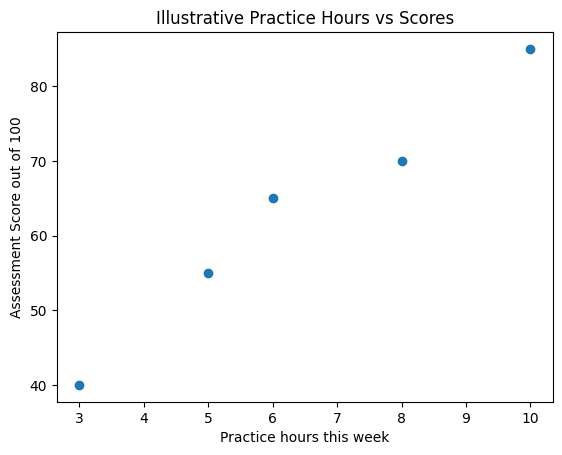

In [ ]:
# Exploring Numerical Relationship
Students
result=Students['hours'].corr(Students['score']) #Pearson Correlation
#Pearson Correlation --> It is a statistcal meausre that quantifies the
#strength and direction of a linear relationship between two continuous variables
# +1.0 --> Perfectly positive--> as variabe x increases,y also increases in a perfect
# -1.0 --> Perfectly negative--> as variabe x increases,y decreases
# st.line
# 0.0(no liner correatlion)-->there is no linear relation b/w variables
result
print('pearson correlation:',round(result,3))
plt.scatter(Students['hours'],Students['score'])
plt.xlabel('Practice hours this week')
plt.ylabel('Assessment Score out of 100')
plt.title('Illustrative Practice Hours vs Scores')
plt.show()

In [ ]:
# Datatypes,Central Tendency and a First look at spread
# Variance,Standard deviation,Quartiles and the IQR rule
# Range --> First measure of spread -->Range= max-min
# student a --> scores --> 58,60,62 --> mean-->60 --> deviations-->-2,0,2
# student b --> scores -->20,60,100-->mean-->60-->deviations-->-40,0,40
# for both students the deviations add to zero.Avg signed deviations would hide the
# spread.Squaring makes the contributions non negative and gives greater weight to larger deviations
# Scores--> a--> deviation as follows
'''
Score x          Mean          Deviations(x-mean)      Squared Deviations
58                60                -2                      4
60                60                 0                      0
62                60                 2                      4

total sqd deviations=4+0+4=8-->population cariance=8/3=2.667 marks squared
population Variance = sum of squared deviations/N
Population Standard deviation =square root (xi-u)/N #xi-->each individual value
u--> population mean
population std deviation --> sqrt(2.667)-->1.663 marks
'''
print(scores_a)
print(scores_b)
mean_a=np.mean(scores_a)
mean_b=np.mean(scores_b)
print(mean_a)
print(mean_b)
dev=scores_a-mean_a
print(dev)
dev2=scores_b-mean_b
print(dev2)
squared_dev=dev**2
squ_dev2=dev2**2
squ_total=np.sum(squared_dev)
squ2_total=np.sum(squ_dev2)
print(squ_total)
print(squ2_total)
Variance_a=squ_total/len(scores_a)
Variance_b=squ2_total/len(scores_b)
print(Variance_a)
print(Variance_b)
std_a=np.sqrt(Variance_a)
std_b=np.sqrt(Variance_b)
print(std_a)
print(std_b)


[58 60 62]
[ 20  60 100]
60.0
60.0
[-2.  0.  2.]
[-40.   0.  40.]
8.0
3200.0
2.6666666666666665
1066.6666666666667
1.632993161855452
32.65986323710904


In [ ]:
# 04-11-2026
# comparing both scores and both denominators
for name,scores in [('A',scores_a,),('B',scores_b)]:
  print(name,'Range:',np.ptp(scores),
        'POP Std:',np.std(scores),
        'Sample std:',np.std(scores,ddof=1))

A Range: 4 POP Std: 1.632993161855452 Sample std: 2.0
B Range: 80 POP Std: 32.65986323710904 Sample std: 40.0


In [ ]:
# Quartiles IQR and Outlier Screening
# values
q1,median,q3=np.percentile(values,
                           [25,50,75],
                           method='linear')
print(q1)
print(q3)
print(median)
iqr=q3-q1
print('Inter Quartile range:',iqr)
lower_fence=q1-1.5*iqr
upper_fence=q3+1.5*iqr
outlier_mask=((values<lower_fence) | (values>upper_fence))
print('Flagged Values:',values[outlier_mask])

15.75
22.0
21.0
Inter Quartile range: 6.25
Flagged Values: [90]


In [ ]:
#Preserve the observations with review labels
review=pd.DataFrame({
    "Observations_Id":np.arange(1,len(values)+1),
    "Values":values,
    "IQR_Flag":outlier_mask
})
review

,Observations_Id,Values,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
d=review.to_string(index=False)
print(d)
print(type(d))

 Observations_Id  Values  IQR_Flag
               1      12     False
               2      15     False
               3      15     False
               4      18     False
               5      20     False
               6      22     False
               7      22     False
               8      22     False
               9      25     False
              10      90      True
<class 'str'>


In [ ]:
review

,Observations_Id,Values,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
print('Flagged IDs:',review.loc[review['IQR_Flag'],'Observations_Id'].tolist())

Flagged IDs: [10]


In [ ]:
print(lower_fence)
print(upper_fence)
print(q1,median)

6.375
31.375
15.75 21.0


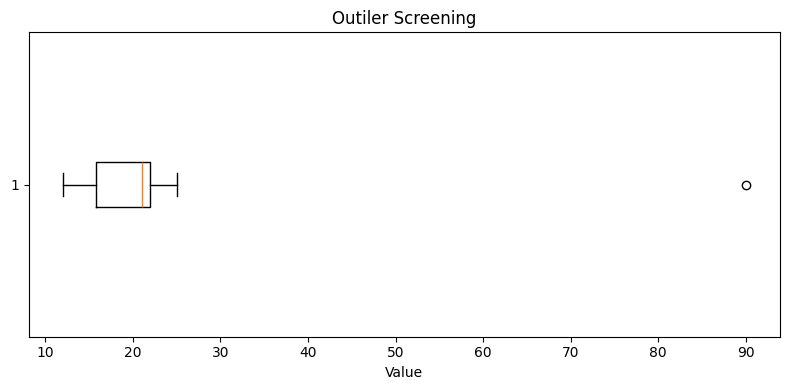

In [ ]:
# python box and whisker plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(values, vert=False)
ax.set_xlabel('Value')
ax.set_title('Outiler Screening')
fig.tight_layout()
plt.show()
# Expecting a box from 15.75 to 22 a median at 21 and separate marker at 90 which indicates outlier
# with whiskers pointing at 6.375 abd upper_fence at 31.375

In [ ]:
# Explain Sensitivity without deleting data
comparision=values[~outlier_mask]
comparision
print('All Mean:',np.mean(values))
print('Comparision Mean:',np.mean(comparision))
print('All Median:',np.median(values))
print('Comparision Median:',np.median(comparision))
#Comparision is only used to demonstrate the sensitivity:values and review still preserve
# the original records

All Mean: 26.1
Comparision Mean: 19.0
All Median: 21.0
Comparision Median: 20.0


Signed Devisations cancel and Squared Devisations reveal
spread Variance uses Squared units, Std used
original units
IQR fences and Box and whsiker plot
endpoints are important
Outlier detection creates a review flag,not
a deletion instruction

In [ ]:
#Postive and Negative Covariance using Paired deviations
#Pearson Correlation from covariance and Std devaitions
#Linear Association from Monotonic Association and Causation
#Python to verify the calculations and inspect scatter plots
Students

,student_id,course,hours,score,satisfaction
0,CGVI0213,DA,5,55,Satisfied
1,CGVI0185,PFS,8,70,Very Satisfied
2,CGVI0206,DA,3,40,Neutral
3,CGVI0176,PFS,10,85,Very Satisfied
4,CGVI0220,DA,6,65,Satisfied


In [ ]:
# create a new observation table
data = pd.DataFrame({
    'Observation': np.arange(1, 7),
    'Practice_Hours': [2, 4, 5, 7, 8, 10],
    'Assessment Score': [35, 48, 55, 68, 74, 90]
})
data

,Observation,Practice_Hours,Assessment Score
0,1,2,35
1,2,4,48
2,3,5,55
3,4,7,68
4,5,8,74
5,6,10,90


In [ ]:
#Variance-->multiplies a variables deviation by itself.
#Co-Variance-->multiplies the deviation in X by the paired deviation in Y.
'''
X deviation               Y deviation         Product       Contribution
Positive                   Positive           Positive      Both above their mean
Negative                   Negative           Positive      Both below their mean
Positive                   Negative           Negative      Opposite sides of their mean
Negative                   Positive           Negative      Opposite sides of their mean


Population Co-Variance = Sum of (xi-population mean of X)*(yi-population mean of Y)
                        -----------------------------------------------------------
                                                  N

Sample Co-Variance = Sum of (xi-sample mean of X)*(yi-sample mean of Y)
                    ----------------------------------------------------
                                        n-1

xi and yi are paired values
N is Population size
n is the sample size
'''


'\nX deviation               Y deviation         Product       Contribution\nPositive                   Positive           Positive      Both above their mean\nNegative                   Negative           Positive      Both below their mean\nPositive                   Negative           Negative      Opposite sides of their mean\nNegative                   Positive           Negative      Opposite sides of their mean\n\n\nPopulation Co-Variance = Sum of (xi-population mean of X)*(yi-population mean of Y)\n                        -----------------------------------------------------------\n                                                  N\n\nSample Co-Variance = Sum of (xi-sample mean of X)*(yi-sample mean of Y)\n                    ----------------------------------------------------\n                                        n-1\n\nxi and yi are paired values\nN is Population size\nn is the sample size\n'

In [ ]:
data[['Practice_Hours','Assessment Score']]
# x-mean x (hours-->x) (mean_x -->x)
# x1-->x1 - mean x -->2-6 --> -4
# x2-->-2
# x3-->-1
# x4-->1
# x5-->2
# x6-->4

#y -mean_y 61.67
# 1 --> -26.67
# 2 -->-13.67
# 3 -->-6.67
# 4 --> 6.33
# 5 -->12.333
# 6 -->28.33

# product --> x1*y1->106.67
# 27.33
# 6.67
# 6.33
# 24.67
# 113.33
# sum of deviation product==285 --> population cov =285/6 -->47.5
# sample covariance=285/5 -->57
# both are positive,indication is more houts --> higer score

,Practice_Hours,Assessment Score
0,2,35
1,4,48
2,5,55
3,7,68
4,8,74
5,10,90


In [ ]:
# 05-11-2026
#Python Co-Variance
hours=np.array([2,4,5,7,8,10],dtype=float)
scores=np.array([35,48,55,68,74,90],dtype=float)
data=pd.DataFrame({'Hours':hours,'Scores':scores})
print('Shape is:',data.shape)
print('Missing Values:',data.isna().sum().to_dict())
# cal co-varaiance from deviations
# we will create the variables as per formula
n=len(hours)
dx=hours-np.mean(hours)
print('dx:',dx)
dy=scores-np.mean(scores)
print('dy:',dy)
product=dx*dy
print(product)
cross_total=np.sum(product)
pop_cov=cross_total/n
sample_cov=cross_total/(n-1)
print('product total:',cross_total)
print('population co-variance',pop_cov)
print('sample co-variance:',sample_cov)


Shape is: (6, 2)
Missing Values: {'Hours': 0, 'Scores': 0}
dx: [-4. -2. -1.  1.  2.  4.]
dy: [-26.66666667 -13.66666667  -6.66666667   6.33333333  12.33333333
  28.33333333]
[106.66666667  27.33333333   6.66666667   6.33333333  24.66666667
 113.33333333]
product total: 285.0
population co-variance 47.5
sample co-variance: 57.0


why standardise co-variance-->
A Co-variance changes in above case if hours are expressed in minutes..


Correlation  divides the co-variance by Standard Deviation of both variables so that the units cancel and mainly  values lies
b/w -1 and +1, provided both variables have non-zero variation

Sample Pearson Correkation-(r)=sample co-varaince(X,Y)
/(sample Std Deviation of X * Sample std Deviation of Y)

for above obervation, sample variance of
hours--> summation(xi-mean_x)**2/n-1
-->(2-6)**2+(4-6)**2+(5-6)**2+(7-6)***2+(8-6)**2+(10-6)**2/5
-->16+4+1+1+4+16/5
Sample Std Deviations-->sqrt(sample variance).-->2.89

Sample variance of scores-->387.466
Sample Std Deviation -->19.6

Sample Pearson Correlation(r)=57/(2.89*19.6)
-->~1 this describes a very strong positive linear association in give 6 observations....


Co-Variance compared with correlation
Property.      Co-varaince.         pearson
Correlation


--->units          product of two units   unitless


-->range.          No fixed bounds.        -1 to +1 defined


->poistive unit rescaling changes magnitude unchanged


-->Purpose. Describes Joint variation. Describe linear  association(direction and strenght)


#A negative rescaling reverses the correlation sign.Adding a constant to either variavle leaves Pearson correlation unchanged...

In [ ]:
# verify and Standardise
cov_matrix=np.cov(hours,scores,ddof=1)
print(cov_matrix)
r_manual=sample_cov/(np.std(hours,ddof=1)*(np.std(scores,ddof=1)))
r=np.corrcoef(hours,scores)[0,1]
print(f'Manual r is  {round(r_manual,4)}')
print(f'Using Numpy value of r is {round(r,4)}')

[[  8.4         57.        ]
 [ 57.         387.46666667]]
Manual r is  0.9991
Using Numpy value of r is 0.9991


In [ ]:
# Ranks adn Careful Analytical conclusions
# Pearson and Spearman
# Pearson measures linear association between numerical variables
# Spearman is pearson correlatio of the ranks and meausres monotonic association
# wheather the consistently tend to increase together or move in opposite....
# Montonic--> It is a trend where two variables movie in a concise relative direction,
# but necessarily at a constant rate....
#Linear-->Perfect st.line
#Montonic-->can be straight line or a curve that never reverses direction

# For x =[1,2,3,4,5],y=[1,4,6,16,25] both rank lists -->[1,2,3,4,5]
# Spearman correaltion-->1
# Pearson Correlation-->0.99
# pandas --> rank() assigns average by default

In [ ]:
# Python unit changes ranks and edge cases
minutes=hours *60
print(minutes)
cov_minutes=np.cov(minutes,scores)[0,1]
print(cov_minutes)
r_minutes=np.corrcoef(minutes,scores)
print(r_minutes)
print('pandas correlation:',data.corr())
# we have receieved Expected co-variance as 3420 minutes *marks ->correlation is making
# same value around 0.991

#cal spearman trought ranks
x_rank_demo=pd.Series([1,2,3,4,5])
y_rank_demo=pd.Series([1,4,9,16,25])
pearson_demo=x_rank_demo.corr(y_rank_demo)
print(pearson_demo)
x_ranks=x_rank_demo.rank()
print('X ranks',x_ranks)
y_ranks=y_rank_demo.rank()
print('Y ranks',y_ranks)
print('Spearman:',round(x_ranks.corr(y_ranks),4))

[120. 240. 300. 420. 480. 600.]
3420.0
[[1.         0.99912089]
 [0.99912089 1.        ]]
pandas correlation:            Hours    Scores
Hours   1.000000  0.999121
Scores  0.999121  1.000000
0.981104910251593
X ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Y ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Spearman: 1.0


[-2. -1.  0.  1.  2.]
[4. 1. 0. 1. 4.]
0.0


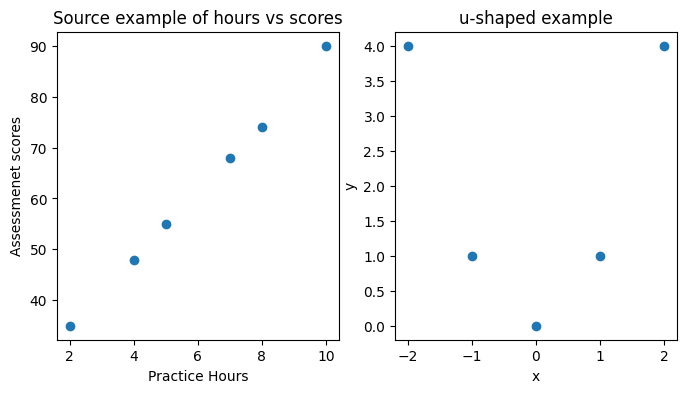

In [ ]:
#Python Scatter plots and nonlinear plots
# compare a line-like pattern with curve
curve_x=np.array([-2,-1,0,1,2],dtype=float)
curve_y=curve_x**2
print(curve_x)
print(curve_y)
curve_r=np.corrcoef(curve_x,curve_y)[0,1]
print(curve_r) # indicates that complete absence of linear ot montonic relationship
# display the plot for above mentioned data
fig,axes=plt.subplots(1,2,figsize=(8,4))
axes[0].scatter(hours,scores)
axes[0].set(xlabel='Practice Hours',ylabel='Assessmenet scores',title='Source example of hours vs scores')
axes[1].scatter(curve_x,curve_y)
axes[1].set(xlabel='x',ylabel='y',title='u-shaped example')
plt.show()

In [ ]:
# 06-11-2026
# task-1
x=np.array([1,2,3])
y=np.array([2,4,6])
dx=x-np.mean(x)
dy=y-np.mean(y)
print('dx:',dx)
print('dy:',dy)
product=dx*dy
print('product:',product)
cross_total=np.sum(product)
pop_cov=cross_total/len(x)
sample_cov=cross_total/(len(x)-1)
print('product total:',cross_total)
print('population co-variance:',pop_cov)
print('sample co-variance:',sample_cov)


dx: [-1.  0.  1.]
dy: [-2.  0.  2.]
product: [2. 0. 2.]
product total: 4.0
population co-variance: 1.3333333333333333
sample co-variance: 2.0


In [ ]:
cov_matrix=np.cov(x,y,ddof=1)
print(cov_matrix)
r_manual=sample_cov/(np.std(x,ddof=1)*(np.std(y,ddof=1)))
r=np.corrcoef(x,y)[0,1]
print(f'Manual r is  {round(r_manual,4)}')
print(f'Using Numpy value of r is {round(r,4)}')

[[1. 2.]
 [2. 4.]]
Manual r is  1.0
Using Numpy value of r is 1.0


Probabilty Distributions-->

It descrubes the possible values of a random
variable and how does probabilty is assigned to them..

It connects uncertainity to the mean,variance and stadard deviation which we have discussed.

Radom Experiment --> It has an outcome that is not know with certainity in advance. A random variable will assign a numerical value to each outcome...we use X for variable...

x or k denotes for possible result

For one Assessment let X=1 (pass),X=0
otherwise --> Let y be nuber of passess..
Let T be time completion in minutes...


Discrte ---> A finite or Countability
infinite set    0,1,2,3,,,,,,,,,calls
in a minute

Continuous---> Any value in a continous
interval ---> task duration in minutes


Oberved Frequencey describe a dataset...

Probability model will describe a proposed mechanism that generates observations....

Eg: 6 passess out of 10 attempts-->

Proportion -->6/10 --> 0.6

A small dataset will not establish exact
probability for every future dataset..




PMF,PDF,CDF

PMF--->Probability Mass Function

-->it gives the exact probability that a discrete random variable equals to a specific value

p(x)=P(X=x)

-->Every probability outcome must be between 0 and 1

-->The sum of all probability across all possible values equal to 1

-->Rolling a 3 on fair six sided die

P(X=3)=1/6

PDF--->Probability Density Function

-->It describes the probability density (likelihood per unit length) of a continuous random variable..(measure like height,
weight,time..)

-->Probability of a cont.variable taking one exact single point always P(X=x)=0

-->It is calculated by area under the curve...

-->Person's height falling between 160cms to 180cms by integrating PDF over that range...


CDF-->Cumulative Density Function

-->It describes the cumulative probability that a random variable is less than or equal to give value (x)--> F(x)=P(X<=x)


-->Can be applied for both discrete and continuous CDF values
0 and 1

-->Discrete variables--> It forms a step function

-->Continuous variables-->It is a smooth, S shaped curve

P(X=4)=1/6 and P(X<=4)=4/6


In [ ]:
import numpy as np
# !pip install scipy
from scipy import stats
import matplotlib.pyplot as plt


In [ ]:
#Bernoulli Distribution--> It models one trial with two possible outcomes
# 1 for Success, 0 for Failure
# P(X=x)=p^x(1-p)^1-x, x E {0,1}
# p-->Probability of X=1; 0<=p<=1
# Support -->0 and 1
# Mean--> P;Variance --> p(1-p);Std-->Sqrt(p(1-p))

p=0.6 #model assigns probability to pass one assessment
pass_prob=stats.bernoulli.pmf(1,p)
fail_prob=stats.bernoulli.pmf(0,p)
bernoulli_mean=p
bernoulli_var=p*(1-p)
bernoulli_std=np.sqrt(bernoulli_var)
print('---bernoulli---')
print('Pass Probability:',round(pass_prob,4))
print('Fail Probability:',round(fail_prob,4))
print('Mean:',bernoulli_mean)
print('Variance:',bernoulli_var)
print('Standard Deviation:',round(bernoulli_std,4))
# p sets the success probability,pass_prob and fail_prob-->exact probabilites
# bernoulli_var describes the therotical variance...

---bernoulli---
Pass Probability: 0.6
Fail Probability: 0.4
Mean: 0.6
Variance: 0.24
Standard Deviation: 0.4899


07-11-2026

Binomial Distribution:
Connection to binary data -->Yes/no-->Bernoulli

Counting how many yes outcomes across a fixed set of independent trials with the same probability leads to Binomial
distribution


A Binomail variable counts successes in a fixed number n of independent Bernoulli trails with the same success probability p...

P(X=k)=(nk)p^k(1-p)n-k
Binomial Coefficient C(n,k)=n!/([k!(n-k)!])
counts the arrangements of k successes amoung n trials

Mean=np,Varaince=np(1-p),Std=sqrt(np(1-p))

In [ ]:
# Assume five independent assessments,each with probabilty 0.6.let x be the total passes.
# For exactly three passes; n=5,k=3,p=0.6
# There are c(5,3)= 5!/3!*2!-->10
# One part,sequence with three passes and to failures has probability
# 0.6**3*0.4**2-->0.03456..Therefore P(X=3)=10*0.03456 -->0.3456
# mean=5*0.6-->3 passes
# Varaince=np(1-p)-->3*(1-0.6)-->3*0.4-->1.2
# Std-->1.09

In [ ]:
# Let us link above scenario to our Python example with exact and cumlative probabilities
n,p=5,0.6
#n---> fixed  trail count, p is the probability per trail pmf(3) only three
#passes.cdf(3)-->probabilities
# for 0 throught 3,sf(2)-->adds probabilities for 3 throught 5
exact_three=stats.binom.pmf(3,n,p)
print('PMF P(X=3)-->',exact_three)
at_most_three=stats.binom.cdf(3,n,p)
print('atmost three--->',round(at_most_three,4))
at_least_three=stats.binom.sf(2,n,p)
print('atleast three-->',round(at_least_three,5))


PMF P(X=3)--> 0.3455999999999997
atmost three---> 0.663
atleast three--> 0.68256


The result is conditional on the model assumptions.Repeated Assessments of the same person may have dependence or different
difficulty.. In that case,a common independent trail binomial
model is suitable


Poisson Distribution---> A Poisson Variable models the number of events in a fixed time,area,distance or a volume..

It processes the events which occur with indepenent increments and a constant rate... The count has no fixed upper limit


P(X=k)=(Lambda^k)(exponential-lambda)/k!,k=0,1,2.....


Lambda-->expected number of events in the specified interval.it must be non negative..

Mean=lamdba,Variance=Lambda...
if the rate is r events per time unit over t units

lamba=r*t

Assume a Support Desk receives calls acccording to poisson process with rate 3 calls per minute..

Over one minute=lambda=3
for exactly 2 calls P(X=2)=e^3*3^2/2!
-->0.2240

For atleast one call,use the complement
P(X>=1)1-P(X=0)=1-e^-3(1)-->0.95

#Over two minutes the expected count becomes 6 not 3


In [ ]:
lam=3 #from above scenario
exact_two=stats.poisson.pmf(2,lam)
print('Exact two:',round(exact_two,2))
at_least_one=stats.poisson.sf(0,lam)
print('At least one:',round(at_least_one,2))
at_least_five=stats.poisson.sf(4,lam)
print('At least five:',round(at_least_five,2))
print('two minute mean:',lam*2)
print('mean:',lam,'variance:',lam)

# Variable roles-->lam stores the expected count per one minute interval..
# Scipy use parameter mu-->lam.Atleast five cases which includes-->5,6,7 and above...


Exact two: 0.22
At least one: 0.95
At least five: 0.18
two minute mean: 6
mean: 3 variance: 3
